NOTE: Logistic Regression ek formula (weighted sum) seekhta tha. Decision Tree if-else sawaalon ka ek flowchart seekhta hai, jaise:

```Recency > 120 din?
 ├─ Haan → Frequency <= 2?
 │          ├─ Haan → CHURN
 │          └─ Nahi → ACTIVE
 └─ Nahi → ACTIVE```

Har node par tree wo feature aur threshold chunta hai jo data ko sabse “saaf” hisson mein todta hai. Saaf hone ka naap Gini impurity hai (0 = ek hi class ke customers, 0.5 = fifty-fifty mix).

Logistic Regression se 3 bade farak:

- Scaling ki zaroorat nahi. Tree sirf thresholds par split karta hai, isliye raw X_train chalega (Day 64 ka point).
- Non-linear patterns pakad leta hai (jaise “Frequency kam aur Recency zyada, dono saath ho tabhi risk”).
- Overfit bahut aasani se hota hai. Bina rok-tok ke tree har training customer ko ratt leta hai.

Aaj ka rule: Test set band hai. Evaluation sirf CV se. Test par dono models ka comparison Day 70 mein hoga.

1. Setup (raw data, scaling nahi):

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree, export_text
from sklearn.model_selection import StratifiedKFold, cross_validate

X_train = pd.read_csv('../../data/processed/X_train.csv')
y_train = pd.read_csv('../../data/processed/y_train.csv').squeeze()

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

# Imbalance handling wahi rakho jo Logistic Regression mein tha (fair comparison ke liye)
CLASS_WEIGHT = 'balanced'     # agar Day 64C mein baseline jeeta tha to None kar do

Tree ke liye SMOTE ke bajaye class_weight rakha hai. Dono models ko compare karna ho to imbalance handling same honi chahiye, aur tree mein class_weight seedha supported hai.

2. Pehla tree: chhota aur readable (max_depth=3):

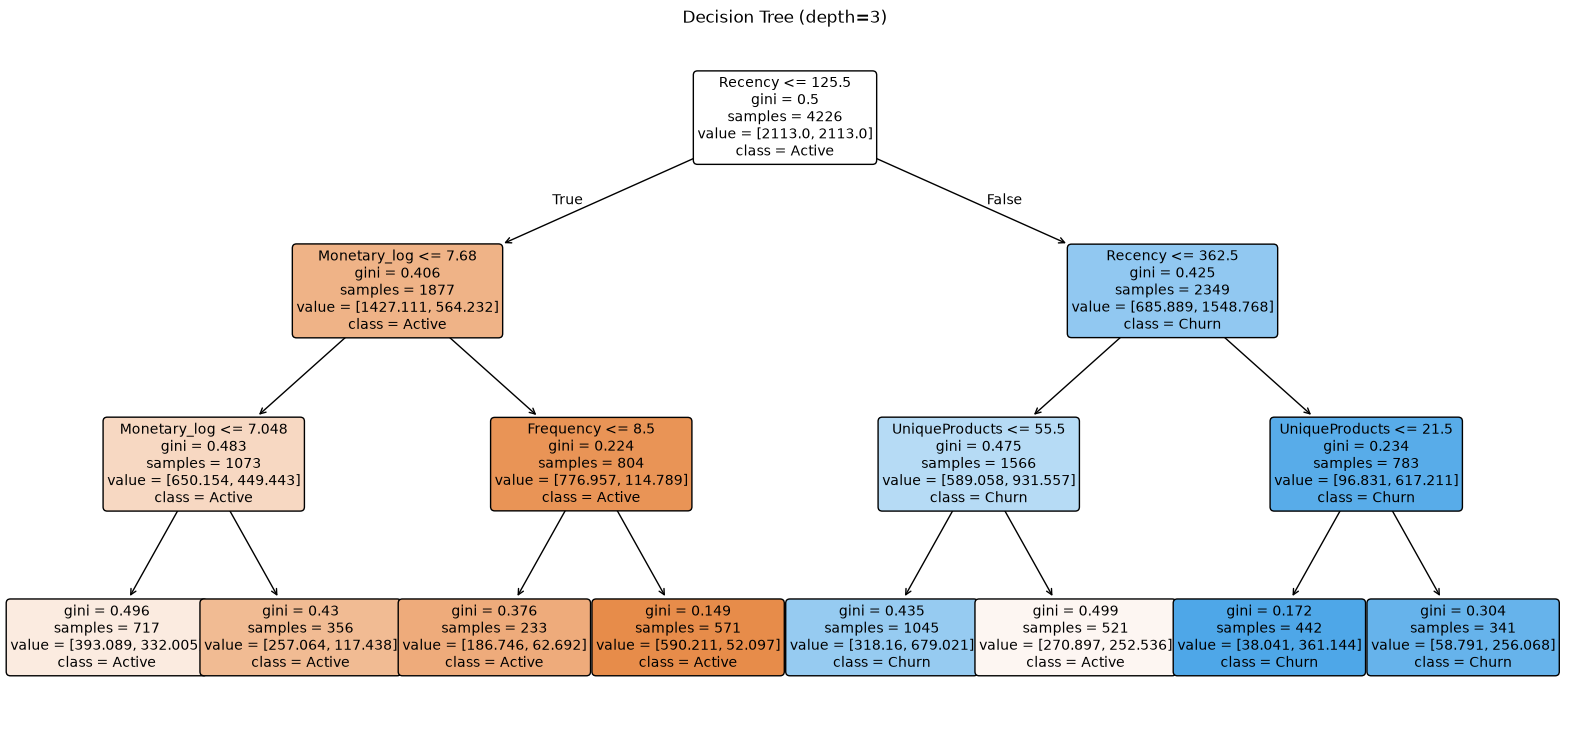

In [2]:
tree = DecisionTreeClassifier(max_depth=3, class_weight=CLASS_WEIGHT, random_state=42)
tree.fit(X_train, y_train)

plt.figure(figsize=(20, 9))
plot_tree(tree, feature_names=X_train.columns, class_names=['Active', 'Churn'],
          filled=True, rounded=True, fontsize=10)
plt.title('Decision Tree (depth=3)')
plt.show()

Chart kaise padho:

- Har box mein: split ka sawaal, gini, samples (kitne customers yahan pahunche), value (har class ke kitne) aur class (majority).
- Rang jitna gehra, node utna “pure”.
- Upar ka split (root) sabse important feature hai.

3. Text version:

In [3]:
print(export_text(tree, feature_names=list(X_train.columns)))

|--- Recency <= 125.50
|   |--- Monetary_log <= 7.68
|   |   |--- Monetary_log <= 7.05
|   |   |   |--- class: 0
|   |   |--- Monetary_log >  7.05
|   |   |   |--- class: 0
|   |--- Monetary_log >  7.68
|   |   |--- Frequency <= 8.50
|   |   |   |--- class: 0
|   |   |--- Frequency >  8.50
|   |   |   |--- class: 0
|--- Recency >  125.50
|   |--- Recency <= 362.50
|   |   |--- UniqueProducts <= 55.50
|   |   |   |--- class: 1
|   |   |--- UniqueProducts >  55.50
|   |   |   |--- class: 0
|   |--- Recency >  362.50
|   |   |--- UniqueProducts <= 21.50
|   |   |   |--- class: 1
|   |   |--- UniqueProducts >  21.50
|   |   |   |--- class: 1



4. Feature importance:

Recency                 0.764
Monetary_log            0.161
UniqueProducts          0.055
Frequency               0.019
AvgOrderValue           0.000
Tenure                  0.000
Region_Rest of World    0.000
Region_UK               0.000
dtype: float64


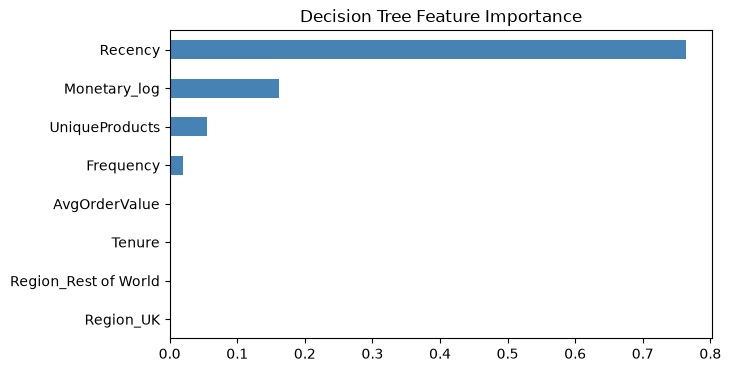

In [4]:
imp = pd.Series(tree.feature_importances_, index=X_train.columns).sort_values(ascending=False)
print(imp.round(3))

imp.sort_values().plot(kind='barh', figsize=(7, 4), color='steelblue')
plt.title('Decision Tree Feature Importance')
plt.show()

Yeh Logistic Regression ke coefficients se alag cheez hai: importance sirf “kitna kaam aaya” batata hai, direction (badhne par risk badhta hai ya ghatta hai) nahi batata. Isme ek caveat bhi hai: yeh continuous features ko thoda favour karta hai. Isi liye Day 85B mein SHAP se confirm karenge.

5. Overfitting ka asli demo (sabse zaroori hissa):

In [5]:
full = DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42).fit(X_train, y_train)

print("Depth of unrestricted tree:", full.get_depth())
print("Number of leaves          :", full.get_n_leaves())
print("Train accuracy:", round(full.score(X_train, y_train), 3))

Depth of unrestricted tree: 36
Number of leaves          : 1066
Train accuracy: 1.0


Train accuracy ~1.0 ke aas-paas aayegi, kyunki tree ne har customer ko ratt liya. Ab dekho ki naye data par kya hota hai:

In [6]:
res_full = cross_validate(
    DecisionTreeClassifier(class_weight=CLASS_WEIGHT, random_state=42),
    X_train, y_train, cv=cv, scoring=metrics, return_train_score=True
)
print(f"Train F1: {res_full['train_f1'].mean():.3f}")
print(f"CV F1   : {res_full['test_f1'].mean():.3f}")

Train F1: 1.000
CV F1   : 0.686


Train aur CV ke beech ka bada gap hi overfitting hai. Yaad karo Day 61 ka toy example.

6. Chhote tree ka CV score (compare karo):

In [7]:
res_small = cross_validate(
    DecisionTreeClassifier(max_depth=3, class_weight=CLASS_WEIGHT, random_state=42),
    X_train, y_train, cv=cv, scoring=metrics, return_train_score=True
)
print(f"Depth=3  -> Train F1: {res_small['train_f1'].mean():.3f} | CV F1: {res_small['test_f1'].mean():.3f}")
print(f"No limit -> Train F1: {res_full['train_f1'].mean():.3f} | CV F1: {res_full['test_f1'].mean():.3f}")

Depth=3  -> Train F1: 0.734 | CV F1: 0.716
No limit -> Train F1: 1.000 | CV F1: 0.686


Chhota tree aam taur par kam train score deta hai lekin CV mein behtar ya barabar rehta hai. Kal (Day 69) hum max_depth aur dusre hyperparameters ko systematically tune karenge.

7. Poora baseline CV table (Logistic Regression ke saath compare karne ke liye):

In [8]:
summary = pd.DataFrame({
    m: [res_small[f'test_{m}'].mean(), res_small[f'test_{m}'].std()] for m in metrics
}, index=['mean', 'std']).T.round(3)
print(summary)

            mean    std
accuracy   0.694  0.016
precision  0.753  0.021
recall     0.687  0.069
f1         0.716  0.031
roc_auc    0.769  0.015


Day 64B ki LogReg CV table se yeh numbers side-by-side dekho. Abhi koi final verdict mat do, tuning ke baad comparison hoga.

8. Ek customer ka raasta (tree kaise decide karta hai):

In [9]:
one = X_train.iloc[[0]]
node_path = tree.decision_path(one).indices
for node in node_path:
    if tree.tree_.children_left[node] == tree.tree_.children_right[node]:
        print(f"-> Leaf (node {node}): predicted {'CHURN' if tree.predict(one)[0] == 1 else 'ACTIVE'}")
    else:
        f = X_train.columns[tree.tree_.feature[node]]
        thr = tree.tree_.threshold[node]
        val = one.iloc[0][f]
        print(f"Node {node}: {f} = {val:.2f} {'<=' if val <= thr else '>'} {thr:.2f}")

Node 0: Recency = 380.00 > 125.50
Node 8: Recency = 380.00 > 362.50
Node 12: UniqueProducts = 14.00 <= 21.50
-> Leaf (node 13): predicted CHURN


Decision Tree ki sabse badi taakat yahi hai ki har prediction ki wajah seedhe padhi ja sakti hai, jo business teams ko samjhana aasan hota hai.

9. Model save karo (Day 70 comparison ke liye):

In [10]:
import joblib, os
os.makedirs('models', exist_ok=True)
joblib.dump(tree, 'models/decision_tree_depth3.joblib')

['models/decision_tree_depth3.joblib']

practice questions:

1. max_depth 1, 2, 3, 5, 8 aur None ke liye train F1 aur CV F1 ek table mein nikaalo. Kis depth ke baad CV F1 badhna band hota hai, aur kis depth ke baad gap badhne lagta hai?

In [11]:
results = []
depths = [1, 2, 3, 5, 8, None]

# Metrics list define karo
metrics = ['accuracy', 'precision', 'recall', 'f1', 'roc_auc']

for d in depths:
    dt = DecisionTreeClassifier(max_depth=d, class_weight=CLASS_WEIGHT, random_state=42)
    
    # yahan scoring=metrics pass karna zaroori hai taaki train_f1 key mil sake
    cv_res = cross_validate(dt, X_train, y_train, cv=cv, scoring=metrics, return_train_score=True)
    
    results.append({
        'max_depth': str(d),
        'Train F1': round(cv_res['train_f1'].mean(), 3),
        'CV F1': round(cv_res['test_f1'].mean(), 3),
        'Gap (Train - CV)': round(cv_res['train_f1'].mean() - cv_res['test_f1'].mean(), 3)
    })

comparison_df = pd.DataFrame(results)
print(comparison_df)

  max_depth  Train F1  CV F1  Gap (Train - CV)
0         1     0.739  0.736             0.003
1         2     0.739  0.736             0.003
2         3     0.734  0.716             0.019
3         5     0.764  0.736             0.028
4         8     0.807  0.701             0.106
5      None     1.000  0.686             0.314


2. Plot ka root split dekh kar apne shabdon mein likho: tree ne sabse pehle kaunsa feature aur threshold chuna, aur kya yeh business sense banata hai?

In [12]:
# Root node ka rule check karne ke liye
print(f"Root Feature: {X_train.columns[tree.tree_.feature[0]]}")
print(f"Threshold   : {tree.tree_.threshold[0]:.2f}")

Root Feature: Recency
Threshold   : 125.50
